**GitHub repository:** https://github.com/2026334-boop/Statistical-Techniques

# Statistical Techniques – CA1
**Student:** Fabiana Scanferla Sandoval (sba24440)
**Module:** Stats for Data Analytics – Higher Diploma in Data Analytics in Business
**Lecturer:** Taufique Ahmed

## 0. The dataset

**Online Retail II** (Chen, 2012) from the UCI Machine Learning Repository.
This dataset contains transaction records from a UK online retail store between December 2009 and December 2011. The store mainly sells gift products, and many customers are wholesalers. Each row is **one product line inside one invoice**.

| Variable | Type | Meaning |
|---|---|---|
| Invoice | Categorical (ID) | Invoice number. If it starts with **"C"**, it is a cancellation |
| StockCode | Categorical (ID) | Product code |
| Description | Categorical | Product name |
| Quantity | Numerical – **discrete** | Units of the product in the line |
| InvoiceDate | Date/time | When the sale happened |
| Price | Numerical – **continuous** | Price of one unit (£) |
| Customer ID | Categorical (ID) | Customer number |
| Country | Categorical – nominal | Country of the customer |

I will also create new variables: Revenue, Region, DayOfWeek, Month and IsCancelled. These variables will help me analyse sales patterns and compare different groups of transactions.

*Reference:* Chen, D. (2012) *Online Retail II* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5CG6D

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from scipy import stats

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold'})
BLUE, ORANGE = '#2a78d6', '#eb6834'   # one colour per group, used the same way in every plot

### 0.1 Load the data
The Excel file contains two sheets. I combined them into one dataset using Python. The final dataset has 1,067,371 rows and 8 columns. I used head() to check the first five rows.

In [2]:
sheets = pd.read_excel('online_retail_II.xlsx', sheet_name=None)
for name, sheet in sheets.items():
    print(f'{name}: {sheet.shape[0]:,} rows')

df = pd.concat(sheets.values(), ignore_index=True)
print(f'\nTotal: {df.shape[0]:,} rows and {df.shape[1]} columns')
df.head()

Year 2009-2010: 525,461 rows
Year 2010-2011: 541,910 rows

Total: 1,067,371 rows and 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [4]:
# Missing values and duplicated rows
missing = pd.DataFrame({'Missing values': df.isna().sum(),
                        '% of rows': (df.isna().mean() * 100).round(2)})
print(missing)
print(f'\nDuplicated rows: {df.duplicated().sum():,}')

             Missing values  % of rows
Invoice                   0       0.00
StockCode                 0       0.00
Description            4382       0.41
Quantity                  0       0.00
InvoiceDate               0       0.00
Price                     0       0.00
Customer ID          243007      22.77
Country                   0       0.00

Duplicated rows: 34,335


**What I see:**
Customer ID is missing in 22.8% of the rows. The reason is unknown. I decided to keep these rows because Customer ID is not required for my main analysis.
- **Description** is missing in only 0.4% of rows (most of them have Price = 0, so they are removed in the cleaning step).
- There are **34,335 duplicated rows** (the same line repeated). These are errors and I remove them.

### 0.2 Cleaning
Steps:
1. Remove exact **duplicated rows**.
2. Create **IsCancelled** = True if the invoice starts with "C". I keep this column because I will use it in Part 2 (Binomial).
3. For the sales analysis I keep only real sales: **not cancelled**, **Quantity > 0** and **Price > 0**.
4. Remove lines that are **not products** (postage, bank charges, discounts, manual adjustments, test products, gift vouchers).
5. Create new variables: **Revenue = Quantity × Price**, Region, Year, Month, DayOfWeek, Hour.

In [5]:
# Count the number of rows before cleaning
steps = [('Original data', len(df))]


# Remove rows that have exactly the same information
df = df.drop_duplicates()

# Save the number of rows after removing duplicates
steps.append(('After removing duplicates', len(df)))


# Identify cancelled invoices
# Cancelled invoice numbers start with the letter C
df['IsCancelled'] = df['Invoice'].astype(str).str.startswith('C')


# Keep only sales that are not cancelled
# Quantity and Price must be greater than zero
sales = df[(~df['IsCancelled']) & (df['Quantity'] > 0) & (df['Price'] > 0)].copy()

# Save the number of valid sales rows
steps.append(('Only real sales (no cancellations, Quantity > 0, Price > 0)', len(sales)))


# List codes that do not represent regular products
# For example: postage, fees, discounts and adjustments
non_products = [
    'POST', 'DOT', 'M', 'm', 'C2', 'C3', 'D', 'S', 'B',
    'BANK CHARGES', 'ADJUST', 'ADJUST2',
    'AMAZONFEE', 'CRUK', 'PADS',
    'TEST001', 'TEST002', 'GIFT'
]


# Convert product codes into text
code_str = sales['StockCode'].astype(str)


# Remove records that are not regular products
sales = sales[
    ~code_str.isin(non_products) &
    ~code_str.str.startswith('gift_')
]

# Save the number of remaining product rows
steps.append(('Only products (no postage, fees, adjustments)', len(sales)))


# Find cancellations with very large quantities
# We will need to check whether removing the matching sales is justified
big_cancel = df[df['IsCancelled'] & (df['Quantity'] <= -10000)]


# Check each large cancellation
for _, r in big_cancel.iterrows():

    # Find sales with the same customer, product and quantity
    wrong = (
        (sales['Customer ID'] == r['Customer ID']) &
        (sales['StockCode'] == r['StockCode']) &
        (sales['Quantity'] == -r['Quantity'])
    )

    # Show information about the cancelled quantity
    print(
        f"Removed: {r['Description']} - "
        f"{-r['Quantity']:,} units "
        f"(cancelled in invoice {r['Invoice']})"
    )

    # Remove the matching sales rows
    sales = sales[~wrong]


# Save the number of rows after removing matching sales
steps.append(('Without the 2 huge orders cancelled minutes later', len(sales)))


# Create new variables for the statistical analysis

# Calculate revenue by multiplying quantity and price
sales['Revenue'] = sales['Quantity'] * sales['Price']


# Divide customers into UK and Non-UK groups
sales['Region'] = np.where(
    sales['Country'] == 'United Kingdom',
    'UK',
    'Non-UK'
)


# Extract the year from the invoice date
sales['Year'] = sales['InvoiceDate'].dt.year


# Extract the year and month from the invoice date
sales['Month'] = sales['InvoiceDate'].dt.to_period('M')


# Find the day of the week for each transaction
sales['DayOfWeek'] = sales['InvoiceDate'].dt.day_name()


# Find the hour of each transaction
sales['Hour'] = sales['InvoiceDate'].dt.hour


# Create a table to show the cleaning steps
cleaning = pd.DataFrame(steps, columns=['Step', 'Rows'])


# Calculate how many rows were removed at each step
cleaning['Rows removed'] = (
    -cleaning['Rows'].diff()
).fillna(0).astype(int)


# Format the numbers to make them easier to read
cleaning['Rows'] = cleaning['Rows'].map('{:,}'.format)


# Display the cleaning summary table
cleaning

Removed: MEDIUM CERAMIC TOP STORAGE JAR - 74,215 units (cancelled in invoice C541433)
Removed: PAPER CRAFT , LITTLE BIRDIE - 80,995 units (cancelled in invoice C581484)


,Step,Rows,Rows removed
0,Original data,"1,067,371",0
1,After removing duplicates,"1,033,036",34335
2,"Only real sales (no cancellations, Quantity > ...","1,007,913",25123
3,"Only products (no postage, fees, adjustments)","1,003,340",4573
4,Without the 2 huge orders cancelled minutes later,"1,003,338",2


**What I see:** After cleaning, I kept 1,003,338 rows, which is approximately 94% of the original dataset. I removed duplicate rows, cancelled transactions and records that were not product sales. I also excluded two very large transactions linked to later cancellations because they could strongly affect the statistical results.

---
# Part 1 – Descriptive statistics

## 1.1 Numerical variables (one row = one product line)
For each numerical variable I calculate the measures we saw in class:
- **Central tendency:** mean, median, mode
- **Dispersion:** standard deviation, variance, range, IQR, coefficient of variation (CV)
- **Position:** minimum, Q1, median, Q3, maximum (five-number summary)
- **Shape:** skewness and kurtosis

**Note about percentiles:** in class we use the position formula **P × (n + 1) / 100**.
`np.percentile` uses a different formula by default, so I use `method='weibull'`, which is the (n + 1) formula from class.

In [6]:
# Check: the class example (slides) gives P25 = 11.25 and P75 = 33.75
example = np.array([5, 10, 15, 20, 25, 30, 35, 40])
print('numpy default   :', np.percentile(example, [25, 75]))
print("method='weibull':", np.percentile(example, [25, 75], method='weibull'), ' <- same as class')

numpy default   : [13.75 31.25]
method='weibull': [11.25 33.75]  <- same as class


In [21]:
# Create a function to calculate descriptive statistics
def describe_variable(x):
    """Descriptive statistics of one numerical variable."""

    # Convert the data into a Series and remove missing values
    x = pd.Series(x).dropna()

    # Calculate the first quartile, median and third quartile
    # Use the same percentile method as in class
    q1, q2, q3 = np.percentile(x, [25, 50, 75], method='weibull')

    # Calculate the main statistical measures
    return pd.Series({

        # Count the number of values
        'Count': len(x),

        # Calculate the mean, median and mode
        'Mean': x.mean(),
        'Median': q2,
        'Mode': x.mode().iloc[0],

        # Calculate how much the values vary
        'Std deviation': x.std(),
        'Variance': x.var(),

        # Find the minimum, quartiles and maximum
        'Min': x.min(),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'Max': x.max(),

        # Calculate the range and interquartile range
        'Range': x.max() - x.min(),
        'IQR': q3 - q1,

        # Calculate the coefficient of variation
        'CV (%)': x.std() / x.mean() * 100,

        # Measure the shape of the distribution
        'Skewness': x.skew(),
        'Kurtosis': x.kurt(),
    })


# Select the three numerical variables for the analysis
num_vars = ['Quantity', 'Price', 'Revenue']

# Calculate descriptive statistics for each variable
desc = pd.DataFrame({
    v: describe_variable(sales[v])
    for v in num_vars
})

# Display the results in a table
desc

,Quantity,Price,Revenue
Count,"1,003,338.00","1,003,338.00","1,003,338.00"
Mean,11.00,3.34,19.33
Median,4.00,2.10,10.08
Mode,1.00,1.25,15.00
Std deviation,67.45,4.75,76.01
Variance,"4,549.27",22.61,"5,777.85"
Min,1.00,0.03,0.06
Q1 (25%),1.00,1.25,4.13
Q3 (75%),12.00,4.13,17.70
Max,"19,152.00","1,157.15","38,970.00"


**Interpretation:**
- **Mean > median in all three variables** (Revenue: mean £19.33 vs median £10.08). This means the data is **skewed to the right**:
  most lines are small, but a few very big lines pull the mean up. For this reason the **median is a better "typical" value** than the mean
  (the same idea as the income example from class).
- **Mode:** the most common quantity is **1 unit**, the most common price is **£1.25**, and the most common revenue per line is **£15**.
- **Skewness** is very high (Revenue = 160.9; a symmetric variable has skewness ≈ 0) and **kurtosis** is extremely high (71,479).
  This means a very long right tail with extreme values.
- The **CV** is very large (Quantity 613%, Revenue 393%), so the data is very spread compared with its mean. Price is more stable (CV 142%).
- **Critical point:** before removing the two cancelled orders, the standard deviation of Revenue was **£199.98**; after removing only **2 lines out of 1 million**,
  it is **£76.01**. The **median did not change (£10.08)**. This shows that the mean and SD are very sensitive to outliers, but the median and IQR are robust.

## 1.2 Outliers
I use the two methods from class:
- **IQR method:** outlier if value < Q1 − 1.5·IQR or value > Q3 + 1.5·IQR
- **Z-score method:** outlier if |Z| > 3, where Z = (X − mean) / SD

In [23]:
# Create a function to identify outliers using two statistical methods
# IQR and Z-score

def outlier_summary(x):
 # Convert the data into a Series and remove missing values
    x = pd.Series(x).dropna()
# Calculate the first and third quartiles  
    q1, q3 = np.percentile(x, [25, 75], method='weibull')
# Calculate the interquartile range (IQR)   
    iqr = q3 - q1
# Calculate the lower and upper limits for detecting outliers   
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
# Count the outliers using the IQR method  
    iqr_out = ((x < low) | (x > high)).sum()
# Count the outliers using the Z-score method 
    z_out = (np.abs(stats.zscore(x)) > 3).sum()
    
# Return the outlier results    
    return pd.Series({'Lower bound (IQR)': low, 'Upper bound (IQR)': high,
                      'Outliers IQR': iqr_out, '% IQR': iqr_out / len(x) * 100,
                      'Outliers Z-score': z_out, '% Z-score': z_out / len(x) * 100})

# Show the outlier results in a table
pd.DataFrame({v: outlier_summary(sales[v]) for v in num_vars})

,Quantity,Price,Revenue
Lower bound (IQR),-15.50,-3.07,-16.23
Upper bound (IQR),28.50,8.45,38.06
Outliers IQR,"53,017.00","75,064.00","82,134.00"
% IQR,5.28,7.48,8.19
Outliers Z-score,"3,963.00","7,061.00","6,081.00"
% Z-score,0.39,0.70,0.61


In [24]:
# Show the 5 sales lines with the highest revenue
sales.nlargest(5, 'Revenue')[['Invoice', 'InvoiceDate', 'Description', 'Quantity', 'Price', 'Revenue', 'Country']]

,Invoice,InvoiceDate,Description,Quantity,Price,Revenue,Country
748132,556444,2011-06-10 15:28:00,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",United Kingdom
432176,530715,2010-11-04 11:36:00,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40",United Kingdom
228042,511465,2010-06-08 12:59:00,PINK PAPER PARASOL,3500,2.55,"8,925.00",United Kingdom
873786,567423,2011-09-20 11:05:00,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72",United Kingdom
578172,540815,2011-01-11 12:55:00,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40",United Kingdom


**Interpretation:**
- The **IQR method** marks **5–8%** of the lines as outliers, but the **Z-score method** marks less than **1%**.
  The difference is because the Z-score uses the mean and SD, and the SD is "inflated" by the extreme values, so it is harder to get |Z| > 3.
  When the data is very skewed, the **IQR method is more reliable**.
- The lower bounds are negative, so all outliers are on the **high side** (big orders), which confirms the **right skew**.
- Looking at the biggest lines, they appear to be real wholesale orders (for example 9,360 T-light holders or a £649.50 picnic basket), rather than obvious mistakes.
  Large orders may be normal in this type of business. For this reason **I keep these outliers** and use the median, IQR and log scales to describe the data.

## 1.3 Invoice level (one row = one order)
A product line is only part of an order. For the business, the **order (invoice)** is more meaningful,
so I group the lines by invoice and calculate the **order value** and the **number of different products** in each order.

In [25]:
# Group sales by invoice to analyse complete orders
orders = (sales.groupby('Invoice')
    # Calculate the total value, products and units for each order                
    .agg(OrderValue=('Revenue', 'sum'),
                     Products=('StockCode', 'nunique'),
                     Units=('Quantity', 'sum'),
                     Region=('Region', 'first'),
                     Country=('Country', 'first'),
                     Date=('InvoiceDate', 'first'))
    # Reset the index to organise the orders table           
    .reset_index())
# Show the total number of orders
print(f'Number of orders: {len(orders):,}')
# Show descriptive statistics for order value, products and units
pd.DataFrame({v: describe_variable(orders[v]) for v in ['OrderValue', 'Products', 'Units']})

Number of orders: 39,514


,OrderValue,Products,Units
Count,"39,514.00","39,514.00","39,514.00"
Mean,490.92,25.11,279.21
Median,301.21,15.00,148.00
Mode,15.00,1.00,1.00
Std deviation,"1,126.84",42.27,"1,070.74"
Variance,"1,269,768.68","1,786.42","1,146,493.53"
Min,0.19,1.00,1.00
Q1 (25%),150.32,6.00,67.00
Q3 (75%),484.36,28.00,289.00
Max,"52,940.94","1,108.00","87,167.00"


In [27]:
# Compare UK and Non-UK orders
region_stats = orders.groupby('Region')['OrderValue'].agg(
    # Calculate the number of orders, mean, median and standard deviation
    Orders='count', Mean='mean', Median='median', Std='std')
# Calculate the coefficient of variation (CV) for each region
region_stats['CV (%)'] = region_stats['Std'] / region_stats['Mean'] * 100
# Calculate the percentage of orders for each region
region_stats['% of orders'] = region_stats['Orders'] / region_stats['Orders'].sum() * 100
# Calculate the share of total revenue for each region
region_stats['% of revenue'] = orders.groupby('Region')['OrderValue'].sum() / orders['OrderValue'].sum() * 100
region_stats

,Orders,Mean,Median,Std,CV (%),% of orders,% of revenue
Region,,,,,,,
Non-UK,3332,853.19,421.37,"1,867.55",218.89,8.43,14.66
UK,36182,457.56,295.07,"1,025.87",224.21,91.57,85.34


**Interpretation:**
- There are **39,514 orders**. A typical order (median) is worth **£301** and has **15 different products**; the mean is higher (£491) because of very big orders.
- At order level the skewness is lower than at line level (18.2 vs 160.9), but it is still clearly **right-skewed**.
- **UK vs Non-UK:** foreign customers make only **8.4% of orders** but **14.7% of revenue**. Their median order (**£421**) is about **43% bigger** than in the UK (**£295**).
One possible explanation is that international customers place larger orders, but more information is needed to understand why. This suggests that Non-UK orders have a higher value on average than UK orders.

## 1.4 Categorical variables
For categorical variables the mean has no meaning, so I use **frequencies, percentages and the mode**.

In [28]:
# Count the number of sales lines for each country
country = pd.DataFrame({'Lines': sales['Country'].value_counts()})

# Calculate the percentage of sales lines for each country
country['% of lines'] = country['Lines'] / country['Lines'].sum() * 100

# Calculate the total revenue for each country
country['Revenue (£)'] = sales.groupby('Country')['Revenue'].sum()

# Calculate the percentage of total revenue for each country
country['% of revenue'] = country['Revenue (£)'] / country['Revenue (£)'].sum() * 100

# Show the number of different countries
print(f"Number of countries: {sales['Country'].nunique()}")

# Show the most frequent country (mode)
print(f"Mode (most frequent country): {sales['Country'].mode()[0]}")

# Show the first 10 countries in the table
country.head(10)

Number of countries: 43
Mode (most frequent country): United Kingdom


,Lines,% of lines,Revenue (£),% of revenue
Country,,,,
United Kingdom,923567,92.05,"16,555,366.17",85.34
EIRE,16913,1.69,"623,414.16",3.21
Germany,15787,1.57,"383,289.00",1.98
France,13160,1.31,"311,090.29",1.60
Netherlands,4981,0.50,"549,773.41",2.83
Spain,3560,0.35,"97,766.75",0.50
Switzerland,3068,0.31,"94,024.59",0.48
Belgium,2911,0.29,"56,993.17",0.29
Portugal,2409,0.24,"47,338.27",0.24


In [29]:
# Create a list with the days of the week
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Get the day of the week from each order date
orders['DayOfWeek'] = orders['Date'].dt.day_name()
# Count the orders for each day of the week
day_table = orders['DayOfWeek'].value_counts().reindex(days, fill_value=0).to_frame('Orders')
# Calculate the percentage of orders for each day
day_table['% of orders'] = day_table['Orders'] / day_table['Orders'].sum() * 100
# Show the results in a table
day_table

,Orders,% of orders
DayOfWeek,,
Monday,6245,15.80
Tuesday,7146,18.08
Wednesday,7115,18.01
Thursday,8167,20.67
Friday,5987,15.15
Saturday,30,0.08
Sunday,4824,12.21


In [30]:
# Cancellations (Yes / No) - this variable will be used for the Binomial distribution in Part 2
# Count cancelled and non-cancelled sales lines
canc = df['IsCancelled'].value_counts().rename({False: 'No', True: 'Yes'}).to_frame('Lines')
# Calculate the percentage of each category
canc['%'] = canc['Lines'] / canc['Lines'].sum() * 100
# Show the cancellation results
canc

,Lines,%
IsCancelled,,
No,1013932,98.15
Yes,19104,1.85


**Interpretation:**
- **Country:** there are 43 countries, but the **mode is the United Kingdom** with **92% of the lines** and **85% of the revenue**.
  The variable is very **unbalanced**. Ireland (EIRE), the Netherlands and Germany are the most important foreign markets.
  The Netherlands has few lines (0.5%) but 2.8% of revenue, so its orders are very large.
- **Day of the week:** **Thursday** is the busiest day (20.7% of orders). There are almost **no orders on Saturday** (only 30 in two years),
  which suggests that Saturday is not a typical ordering day. This is important for Part 2 because I need to consider the low number of Saturday orders when analysing daily sales.
- **Cancellations:** **1.85%** of all lines are cancellations. This is a **yes/no** variable, so it is perfect for the **Binomial distribution** in Part 2.

## 1.5 Correlation between numerical variables
Because the variables are very skewed and have many outliers, I use **Spearman** correlation
(based on ranks), which is less affected by extreme values than Pearson.

In [31]:
# Show the Spearman correlation results
print('Spearman correlation (product lines):')
# Calculate Spearman correlation between numerical variables
print(sales[num_vars].corr(method='spearman').round(2))
# Show the Pearson correlation results for comparison
print('\nPearson correlation, for comparison:')
# Calculate Pearson correlation between numerical variables
print(sales[num_vars].corr(method='pearson').round(2))

Spearman correlation (product lines):
          Quantity  Price  Revenue
Quantity      1.00  -0.43     0.69
Price        -0.43   1.00     0.30
Revenue       0.69   0.30     1.00

Pearson correlation, for comparison:
          Quantity  Price  Revenue
Quantity      1.00  -0.05     0.41
Price        -0.05   1.00     0.15
Revenue       0.41   0.15     1.00


**Interpretation:**
- **Quantity and Price** have a **negative** Spearman correlation (**−0.43**): Lower-priced products tend to be bought in larger quantities, while higher-priced products tend to be bought in smaller quantities.
  This makes sense for a wholesale business.
- **Quantity → Revenue** (0.69) is stronger than **Price → Revenue** (0.30). This suggests that quantity has a stronger relationship with revenue than price does. 
- **Pearson** gives much weaker values (for example −0.05 for Quantity–Price). Pearson measures *linear* relations and is affected by outliers,
 so the results may be affected by extreme values. Spearman is more suitable for describing the relationships in this dataset.   

---
## 1.6 Plots

### Plot 1 – Histogram of Revenue per line (normal scale vs log scale)
**Why this plot?** A histogram shows the **shape** of a numerical variable (where most values are, skewness, long tails).
Because Revenue is very skewed, in the normal scale I only show values up to the 99th percentile,
and on the right I use a **log scale** so we can see the whole distribution.

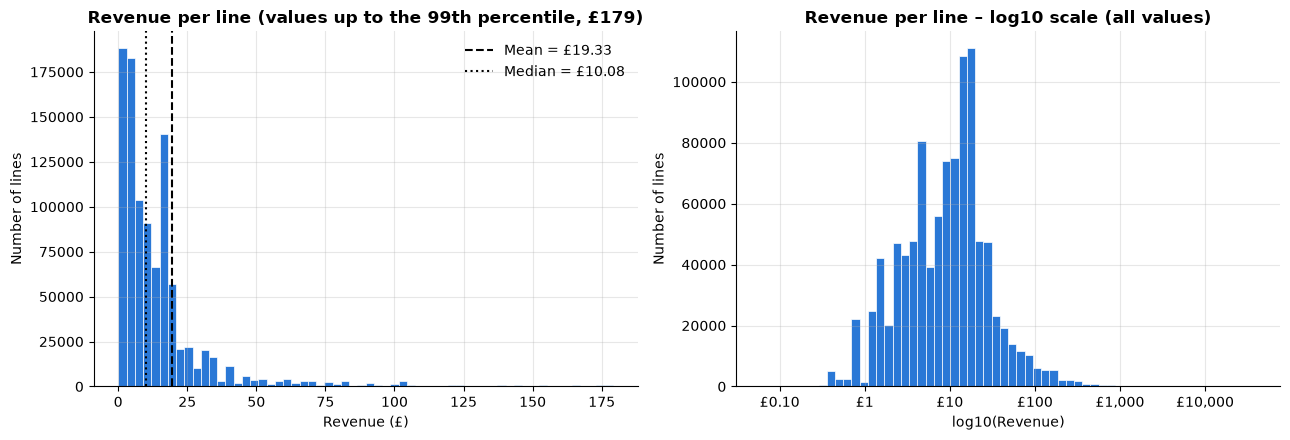

In [32]:
# Calculate the 99th percentile of revenue
p99 = np.percentile(sales['Revenue'], 99)
# Calculate the mean and median of revenue
mean_r, median_r = sales['Revenue'].mean(), sales['Revenue'].median()

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Create a histogram of revenue up to the 99th percentile
axes[0].hist(sales.loc[sales['Revenue'] <= p99, 'Revenue'], bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
# Add a vertical line to show the mean revenue
axes[0].axvline(mean_r, color='black', linestyle='--', linewidth=1.5, label=f'Mean = £{mean_r:.2f}')
# Add a vertical line to show the median revenue
axes[0].axvline(median_r, color='black', linestyle=':', linewidth=1.5, label=f'Median = £{median_r:.2f}')
# Add a title and labels to the first histogram
axes[0].set(title=f'Revenue per line (values up to the 99th percentile, £{p99:.0f})',
            xlabel='Revenue (£)', ylabel='Number of lines')
# Show the legend for the mean and median
axes[0].legend(frameon=False)

# Create a histogram using the log10 scale
axes[1].hist(np.log10(sales['Revenue']), bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
# Add a title and labels to the second histogram
axes[1].set(title='Revenue per line – log10 scale (all values)', xlabel='log10(Revenue)', ylabel='Number of lines')
# Format the numbers on the horizontal axis
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'£{10**v:,.2f}' if v < 0 else f'£{10**v:,.0f}'))
# Adjust the spacing between the plots
plt.tight_layout()
# Display the plots
plt.show()

**Interpretation:** the left histogram shows a strong **right skew**: most lines are below £20, and the mean (£19.33) is almost **double the median** (£10.08).
The tall bars around £15 and £17.70 show that many sales lines have revenue values in these ranges.
In the **log scale** (right) the distribution looks much more **symmetric, almost like a bell**. 
This suggests that the log-transformed revenue is more symmetric, but further analysis is needed to confirm its distribution.
I will use this idea in Part 3 (Normal distribution).

### Plot 2 – Boxplot of order value: UK vs Non-UK
**Why this plot?** A boxplot shows the **five-number summary** and the **outliers**, and it is the best plot
to **compare a numerical variable between groups** (here, the two regions). I use a log scale because of the extreme values.

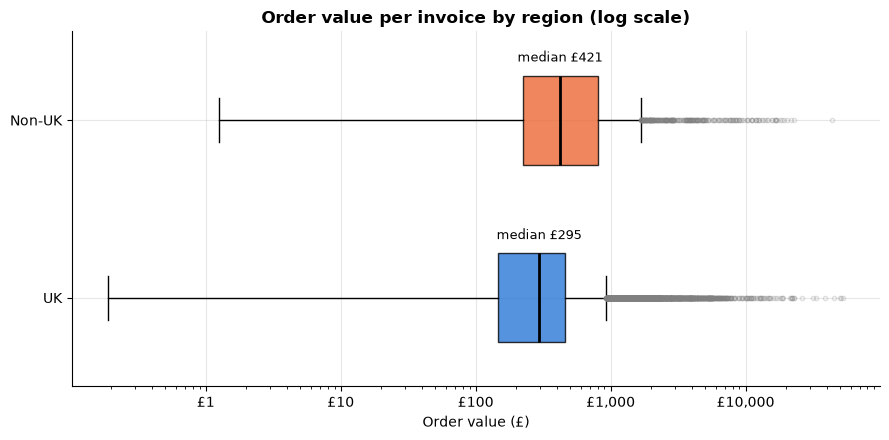

In [34]:
# Create a figure for the boxplot
fig, ax = plt.subplots(figsize=(9, 4.5))
# Get the order values for UK and Non-UK
data = [orders.loc[orders['Region'] == r, 'OrderValue'] for r in ['UK', 'Non-UK']]
# Create horizontal boxplots to compare both regions
bp = ax.boxplot(data, orientation='horizontal' , patch_artist=True, widths=0.5,
                flierprops=dict(marker='o', markersize=3, alpha=0.25, markeredgecolor='grey'),
                medianprops=dict(color='black', linewidth=2))
# Add labels for the two regions
ax.set_yticks([1, 2], ['UK', 'Non-UK'])
# Set different colours for UK and Non-UK
for patch, colour in zip(bp['boxes'], [BLUE, ORANGE]):
    patch.set_facecolor(colour); patch.set_alpha(0.8)
# Use a log scale because order values vary a lot
ax.set_xscale('log')
# Format the numbers on the horizontal axis
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'£{v:,.2f}' if v < 1 else f'£{v:,.0f}'))
# Add the median value above each boxplot
for i, d in enumerate(data, start=1):
    ax.text(d.median(), i + 0.33, f'median £{d.median():,.0f}', ha='center', fontsize=9)
# Add the chart title and horizontal axis label
ax.set(title='Order value per invoice by region (log scale)', xlabel='Order value (£)')
# Adjust the spacing of the chart
plt.tight_layout()
# Display the boxplot
plt.show()

**Interpretation:** the **Non-UK box is further to the right**, so foreign orders are bigger in general, not only on average.
Both groups have **many outliers on the right** (big orders), which again shows the right skew.
The UK has many more orders (36,182 vs 3,332), so it is important to consider the different group sizes when comparing outliers.

### Plot 3 – Monthly revenue (line chart)
**Why this plot?** The data covers two years, so a **line chart over time** is the best way to see **trends and seasonality**.
December 2011 is excluded because the data stops on 9 December (it is not a full month).

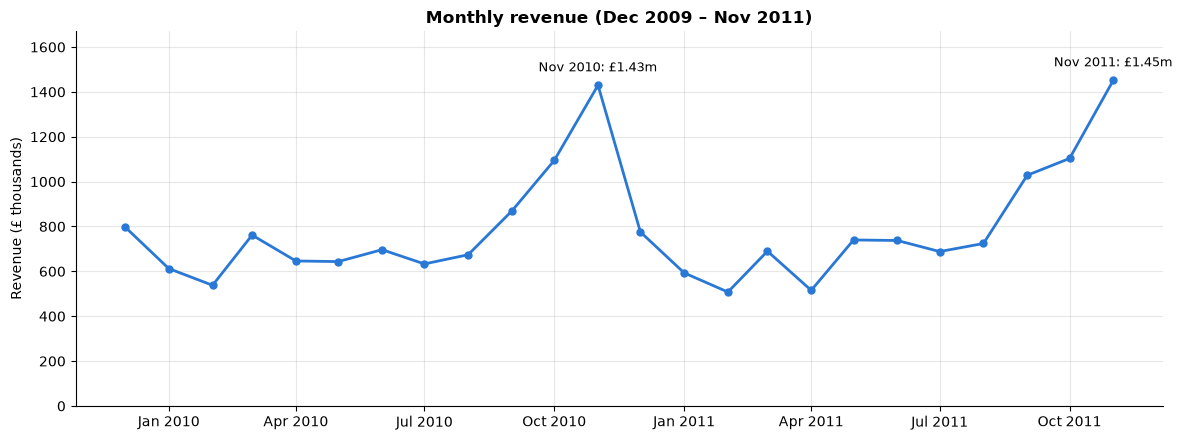

In [35]:
# Calculate the total revenue for each month
monthly = sales.groupby('Month')['Revenue'].sum()
# Remove December 2011 because it is incomplete
monthly = monthly[monthly.index < pd.Period('2011-12', 'M')]   # remove incomplete month
# Create a figure for the line chart
fig, ax = plt.subplots(figsize=(12, 4.5))
# Create a figure for the line chart
x = monthly.index.to_timestamp()
# Plot monthly revenue in thousands of pounds
ax.plot(x, monthly.values / 1000, color=BLUE, linewidth=2, marker='o', markersize=5)
# Find the two months with the highest revenue
top2 = monthly.nlargest(2)
# Add labels to the two highest points
for p, v in top2.items():
    ax.annotate(f'{p.strftime("%b %Y")}: £{v/1e6:.2f}m', (p.to_timestamp(), v / 1000),
                textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
# Format the dates on the horizontal axis
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
# Add the chart title and axis labels
ax.set(title='Monthly revenue (Dec 2009 – Nov 2011)', ylabel='Revenue (£ thousands)', xlabel='')
# Set the vertical axis limits
ax.set_ylim(0, monthly.max() / 1000 * 1.15)
# Adjust the spacing of the chart
plt.tight_layout()
# Display the line chart
plt.show()

**Interpretation:** there is a very clear **seasonal pattern** that repeats in both years:
revenue grows from **September** and reaches the maximum in **November** (about **£1.43–1.45 million**, around double a normal month of £0.5–0.8 million).
One possible explanation is that shops buy more stock before Christmas, but more information would be needed to confirm this. The lowest month in both years is **February**.
For the business, this means stock and staff must be planned for the autumn peak. The two years are very similar, so the pattern is stable.

### Plot 4 – Number of orders by day of the week and by hour
**Why this plot?** DayOfWeek is a **categorical** variable, so a **bar chart** of frequencies is the right plot.
The hour plot shows *when* orders arrive. This is also useful for Part 2 (Poisson = number of events in a time period).

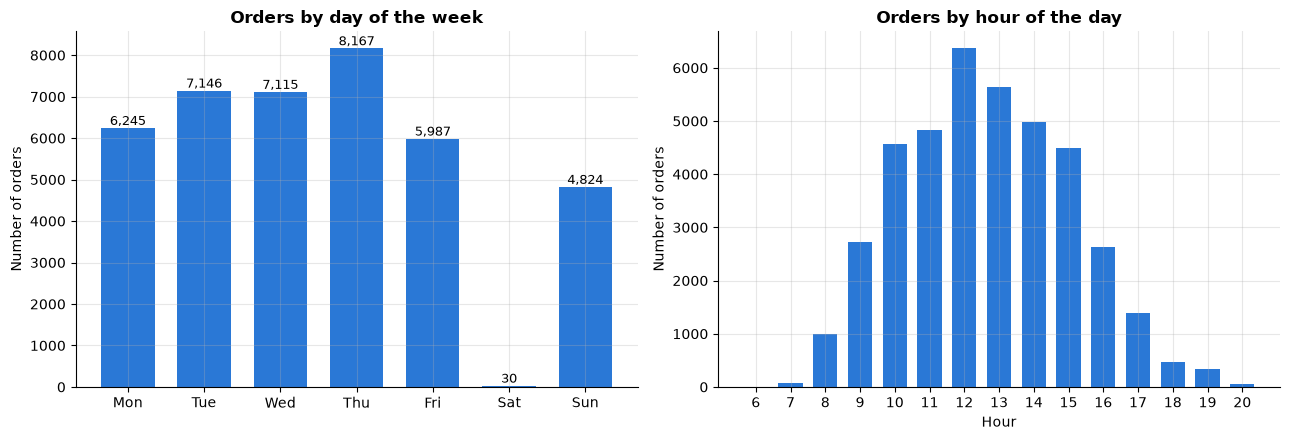

In [36]:
# Count the number of orders for each hour
hours = orders['Date'].dt.hour.value_counts().sort_index()
# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Create a bar chart for orders by day of the week
axes[0].bar([d[:3] for d in days], day_table['Orders'], color=BLUE, width=0.7)

# Add the number of orders above each bar
for i, v in enumerate(day_table['Orders']):
    
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
# Add the title and label to the first chart
axes[0].set(title='Orders by day of the week', ylabel='Number of orders')

# Create a bar chart for orders by hour
axes[1].bar(hours.index, hours.values, color=BLUE, width=0.7)
# Add the title and labels to the second chart
axes[1].set(title='Orders by hour of the day', xlabel='Hour', ylabel='Number of orders')
# Show the hours on the horizontal axis
axes[1].set_xticks(hours.index)
# Adjust the spacing between the charts
plt.tight_layout()
# Display both charts
plt.show()

**Interpretation:**
- **Day of week:** orders are spread from Monday to Friday and Sunday, with a peak on **Thursday**; Saturday is almost **zero**.
- **Hour:** Most orders are placed between 8:00 and 17:00, with the highest number at 12:00. The number of orders increases during the morning and decreases in the afternoon.
- Because orders are **counted in a time period** (per day or per hour), this variable is a good candidate for the **Poisson distribution** in Part 2.

### Plot 5 – Top 10 countries outside the UK by revenue
**Why this plot?** Country is a **categorical** variable with many levels. A **horizontal bar chart**, sorted,
makes it easy to compare them. The UK is not in the chart because it is so big that the other bars would be too small to read.

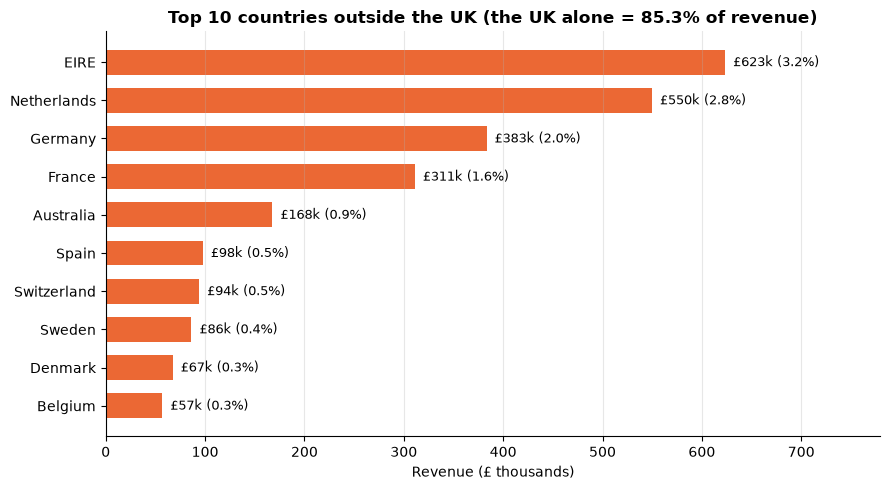

In [37]:
# Select the top 10 countries outside the UK by revenue
top_c = country.drop('United Kingdom').nlargest(10, 'Revenue (£)').iloc[::-1]

# Create a figure for the bar chart
fig, ax = plt.subplots(figsize=(9, 5))
# Create a horizontal bar chart
ax.barh(top_c.index, top_c['Revenue (£)'] / 1000, color=ORANGE, height=0.65)
# Add revenue values and percentages next to each bar
for i, (v, pct) in enumerate(zip(top_c['Revenue (£)'], top_c['% of revenue'])):
    ax.text(v / 1000, i, f'  £{v/1000:,.0f}k ({pct:.1f}%)', va='center', fontsize=9)
# Calculate the percentage of revenue from the UK
uk_share = country.loc['United Kingdom', '% of revenue']
# Add the chart title and horizontal axis label
ax.set(title=f'Top 10 countries outside the UK (the UK alone = {uk_share:.1f}% of revenue)',
       xlabel='Revenue (£ thousands)')
# Set the horizontal axis limits
ax.set_xlim(0, top_c['Revenue (£)'].max() / 1000 * 1.25)
# Hide the horizontal grid lines
ax.grid(axis='y', visible=False)
# Adjust the spacing of the chart
plt.tight_layout()
# Display the bar chart
plt.show()

**Interpretation:** Outside the UK, the main markets are **Ireland (3.2%)**, the **Netherlands (2.8%)**, **Germany (2.0%)** and **France (1.6%)**. These are all European markets. Australia is the only country outside Europe in the top five. All Non-UK countries together represent about **15% of total revenue**, showing that the business depends heavily on the UK market. This could be a risk, but it also shows an opportunity to increase sales in other countries.

---
## 1.7 Summary of Part 1

1. **Numerical variables**: Quantity, Price and Revenue are strongly right-skewed. The median and IQR help describe typical values because the data contain extreme values.
2. **Outliers**: Many extreme values may be genuine wholesale orders, so I kept them in the analysis. Two very large cancelled orders were removed during data cleaning. After removing them, the standard deviation of Revenue was approximately £76.
3. **Revenue distribution**: Revenue is strongly right-skewed. After applying a log transformation, the distribution looks more symmetric. This will be explored further in Part 3.
4. **Correlation**: Quantity and Price have a negative Spearman correlation (−0.43). This suggests that lower-priced products tend to be purchased in larger quantities.
5. **UK and Non-UK sales**: The UK represents approximately 92% of sales lines and 85% of total revenue. The median order value is £295 for the UK and £421 for Non-UK orders.
6. **Seasonality**: November has the highest monthly revenue in both years. This suggests a seasonal pattern, with higher sales during autumn.
7. **Orders by day and hour**: Thursday has the highest number of orders, while Saturday has very few. The busiest hour is 12:00.
8. **Variables for the next parts**: IsCancelled (Yes/No) will be used for the Binomial distribution, orders per day for the Poisson distribution, and Revenue and order values will be explored in Part 3 (Normal distribution).

# Part 2 – Probability Distributions

## 2.1 Binomial Distribution

The binomial distribution is used when there are two possible outcomes.

In this dataset, I will study whether a transaction is cancelled or not cancelled.

I will calculate the probability of cancellation and use the binomial distribution to estimate probabilities for a fixed number of transactions.

In [39]:
# Count cancelled and non-cancelled transactions
df['IsCancelled'].value_counts()

IsCancelled
False    1013932
True       19104
Name: count, dtype: int64

In [40]:
# Calculate the probability of cancellation
p_cancel = df['IsCancelled'].mean()

# Show the probability as a percentage
print(f"Cancellation probability: {p_cancel:.4f}")
print(f"Cancellation percentage: {p_cancel * 100:.2f}%")

Cancellation probability: 0.0185
Cancellation percentage: 1.85%


In [41]:
# Check the number of unique invoices
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'IsCancelled']


In [42]:
# Check cancellations for each invoice
invoice_cancel = df.groupby('Invoice')['IsCancelled'].max()

# Count cancelled and non-cancelled invoices
print(invoice_cancel.value_counts())

IsCancelled
False    45336
True      8292
Name: count, dtype: int64


In [43]:
# Calculate the probability of a cancelled invoice
p_invoice = invoice_cancel.mean()

# Show the probability and percentage
print(f"Cancellation probability: {p_invoice:.4f}")
print(f"Cancellation percentage: {p_invoice * 100:.2f}%")

Cancellation probability: 0.1546
Cancellation percentage: 15.46%


In [44]:
# Calculate the probability of exactly 2 cancellations in 10 invoices
n = 10
k = 2

prob_2 = stats.binom.pmf(k, n, p_invoice)

# Show the result
print(f"Probability of exactly 2 cancellations: {prob_2:.4f}")
print(f"Percentage: {prob_2 * 100:.2f}%")

Probability of exactly 2 cancellations: 0.2806
Percentage: 28.06%


**Interpretation:**

The probability of cancellation for one invoice is approximately 15.46%.

Using the Binomial distribution, I calculated the probability of exactly 2 cancelled invoices out of 10 invoices.

The result is 28.06%. This means there is approximately a 28% chance that exactly 2 out of 10 invoices will be cancelled.

This calculation assumes that invoices are independent and have the same probability of cancellation.

In [45]:
# Calculate the probability of at most 2 cancellations in 10 invoices
prob_at_most_2 = stats.binom.cdf(2, n, p_invoice)

# Show the result
print(f"Probability of at most 2 cancellations: {prob_at_most_2:.4f}")
print(f"Percentage: {prob_at_most_2 * 100:.2f}%")

Probability of at most 2 cancellations: 0.8081
Percentage: 80.81%


**Interpretation:**

The probability of at most 2 cancellations out of 10 invoices is 80.81%.

This includes the probability of 0, 1 or 2 cancelled invoices.

I used the cumulative Binomial distribution (CDF) to calculate this probability.

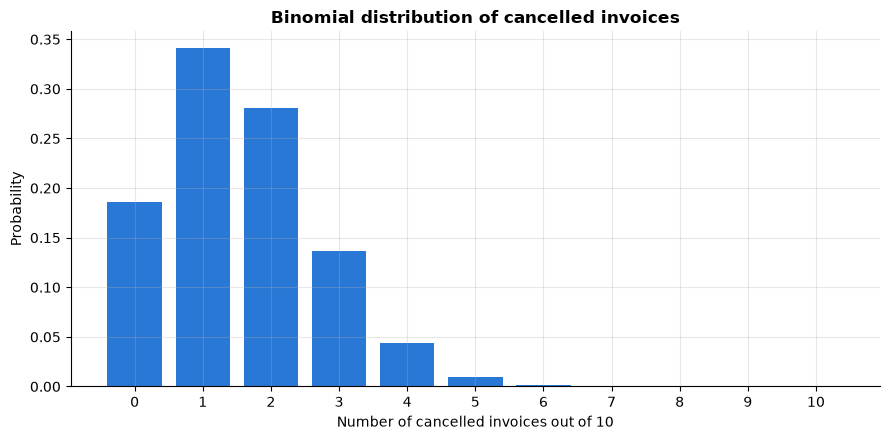

In [46]:
# Calculate the probabilities for 0 to 10 cancelled invoices
x = np.arange(0, 11)
probabilities = stats.binom.pmf(x, n, p_invoice)

# Create a bar chart
plt.figure(figsize=(9, 4.5))
plt.bar(x, probabilities, color=BLUE)

# Add the chart title and labels
plt.title('Binomial distribution of cancelled invoices')
plt.xlabel('Number of cancelled invoices out of 10')
plt.ylabel('Probability')
plt.xticks(x)

# Display the chart
plt.tight_layout()
plt.show()

**Interpretation:**

The chart shows the Binomial distribution for the number of cancelled invoices out of 10.

The most likely result is 1 cancelled invoice. The probability of exactly 2 cancellations is 28.06%.

The probability becomes smaller as the number of cancellations increases beyond 2.

This model uses a cancellation probability of 15.46% for each invoice.

## 2.2 Poisson Distribution

The Poisson distribution is used to calculate the probability of a number of events happening during a fixed period of time.

In this dataset, I will study the number of orders received per day.

First, I will calculate the average number of orders per day. Then, I will use the Poisson distribution to calculate probabilities.

In [47]:
# Count the number of orders for each day
daily_orders = orders.groupby(orders['Date'].dt.date).size()

# Calculate the average number of orders per day
lambda_daily = daily_orders.mean()

# Show the result
print(f"Average orders per day (lambda): {lambda_daily:.2f}")

Average orders per day (lambda): 65.42


In [48]:
# Calculate the probability of exactly 65 orders in one day
k = 65

prob_65 = stats.poisson.pmf(k, lambda_daily)

# Show the result
print(f"Probability of exactly 65 orders: {prob_65:.4f}")
print(f"Percentage: {prob_65 * 100:.2f}%")

Probability of exactly 65 orders: 0.0494
Percentage: 4.94%


**Interpretation:**

The average number of orders per recorded day is 65.42.

Using the Poisson distribution, I calculated the probability of receiving exactly 65 orders in one day.

The result is 4.94%. This means that, according to the Poisson model, there is approximately a 4.94% chance of receiving exactly 65 orders in one day.

This calculation assumes that orders occur independently and at a constant average rate.

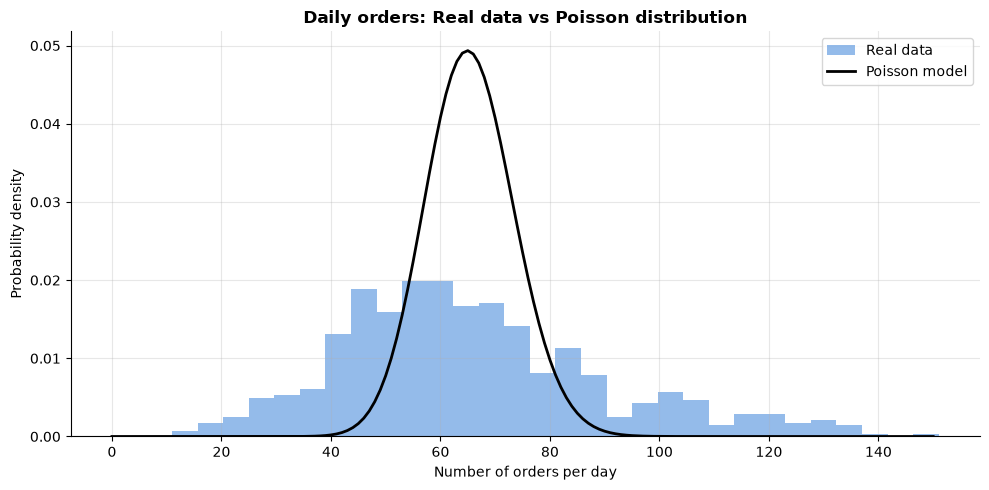

In [49]:
# Calculate the Poisson probabilities
x = np.arange(0, 151)
poisson_probs = stats.poisson.pmf(x, lambda_daily)

# Create a chart
fig, ax = plt.subplots(figsize=(10, 5))

# Show the real number of orders per day
ax.hist(daily_orders, bins=30, density=True,
        alpha=0.5, color=BLUE, label='Real data')

# Show the Poisson model
ax.plot(x, poisson_probs, color='black',
        linewidth=2, label='Poisson model')

# Add the title and labels
ax.set_title('Daily orders: Real data vs Poisson distribution')
ax.set_xlabel('Number of orders per day')
ax.set_ylabel('Probability density')
ax.legend()

# Display the chart
plt.tight_layout()
plt.show()

**Interpretation:**

The average number of orders per recorded day is 65.42.

The blue bars show the real number of orders per day, while the black line shows the Poisson model.

The real data have a wider distribution than the Poisson model. This means that the number of orders varies more than the model predicts.

One possible reason is that the number of orders changes depending on the day of the week.

Therefore, the Poisson distribution is useful for calculating probabilities, but it does not perfectly represent the real data.


In [50]:
# Calculate the mean of daily orders
mean_orders = daily_orders.mean()

# Calculate the variance of daily orders
variance_orders = daily_orders.var()

# Show the results
print(f"Mean of daily orders: {mean_orders:.2f}")
print(f"Variance of daily orders: {variance_orders:.2f}")

Mean of daily orders: 65.42
Variance of daily orders: 598.34


**Interpretation:**

The average number of orders per day is 65.42, while the variance is 598.34.

For a Poisson distribution, the mean and variance should be approximately equal. However, the variance in this dataset is much higher than the mean.

This is called **overdispersion**. It means that the number of daily orders varies more than the Poisson model predicts.

Therefore, the Poisson distribution is not a perfect fit for this dataset.


### 2.3 Large Sample Behaviour

When the number of trials increases, the Binomial distribution can become approximately Normal, provided that both np and n(1-p) are sufficiently large.

In this analysis, the probability of invoice cancellation is 0.1546. For a larger sample of invoices, the Binomial distribution would become more bell-shaped.

For the Poisson distribution, when the average number of events (lambda) is large, the theoretical distribution also becomes approximately Normal.

In this dataset, lambda = 65.42, which is large enough for the theoretical Poisson distribution to have an approximately bell-shaped appearance.

However, the observed daily orders have a variance of 598.34, much higher than the mean of 65.42. This means that even with a large dataset, the Poisson model does not perfectly represent the actual variation in daily orders.

Therefore, larger samples can improve the stability of estimates, but they do not automatically make an unsuitable statistical model fit the data.

# Part 3 – Normal Distribution

## 3.1 Exploring the Distribution of Unit Prices

In [52]:
# Part 3 - Normal Distribution
# Explore the distribution of unit prices

# Select valid positive prices
prices = df.loc[df['Price'] > 0, 'Price'].dropna()

# Calculate descriptive statistics
mean_price = prices.mean()
std_price = prices.std()
skew_price = prices.skew()

# Display results
print(f"Mean unit price: {mean_price:.2f}")
print(f"Standard deviation: {std_price:.2f}")
print(f"Skewness: {skew_price:.2f}")
print(f"Number of observations: {len(prices)}")

Mean unit price: 4.80
Standard deviation: 93.11
Skewness: 182.74
Number of observations: 1027017


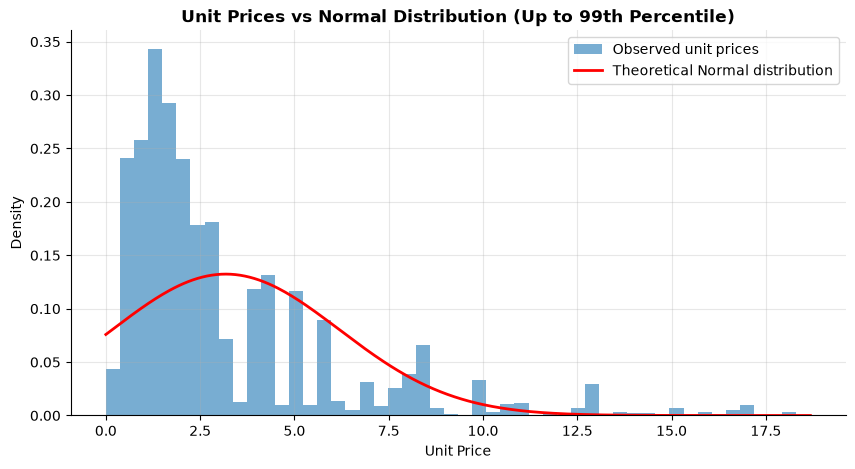

99th percentile price: 18.68


In [53]:
# Compare actual unit prices with a theoretical Normal distribution

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Focus on prices up to the 99th percentile for clearer visualisation
price_limit = prices.quantile(0.99)
prices_plot = prices[prices <= price_limit]

# Calculate statistics for the displayed subset
plot_mean = prices_plot.mean()
plot_std = prices_plot.std()

# Create values for the Normal curve
x = np.linspace(0, price_limit, 300)
normal_curve = stats.norm.pdf(x, plot_mean, plot_std)

# Plot histogram and Normal curve
plt.figure(figsize=(10, 5))
plt.hist(prices_plot, bins=50, density=True,
         alpha=0.6, label='Observed unit prices')

plt.plot(x, normal_curve, color='red', linewidth=2,
         label='Theoretical Normal distribution')

plt.title('Unit Prices vs Normal Distribution (Up to 99th Percentile)')
plt.xlabel('Unit Price')
plt.ylabel('Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"99th percentile price: {price_limit:.2f}")

### Interpretation: Normal Distribution of Unit Prices

The analysis of unit prices produced a mean of 4.80 and a standard deviation of 93.11.

The skewness was 182.74, indicating an extremely positively skewed distribution. This suggests that most unit prices are relatively low, while a small number of observations have exceptionally high prices.

The histogram was limited to the 99th percentile (18.68) to improve visualisation. The theoretical Normal curve was calculated using the mean and standard deviation of this displayed subset.

The observed histogram differs considerably from the theoretical Normal curve. Most prices are concentrated at lower values, with a long tail extending towards higher prices.

Therefore, unit prices do not appear to follow a Normal distribution. This demonstrates why it is important to examine the shape of the data before selecting a statistical model.

In [54]:
# Check the Empirical Rule (68-95-99.7)
# Use the full positive-price dataset

for n in [1, 2, 3]:
    lower = mean_price - n * std_price
    upper = mean_price + n * std_price

    percentage = (
        ((prices >= lower) & (prices <= upper)).mean() * 100
    )

    print(f"Within {n} standard deviation(s): {percentage:.2f}%")

Within 1 standard deviation(s): 99.81%
Within 2 standard deviation(s): 99.88%
Within 3 standard deviation(s): 99.92%


### 3.2 Empirical Rule (68-95-99.7)

The Empirical Rule states that approximately 68%, 95% and 99.7% of observations in a Normal distribution fall within one, two and three standard deviations of the mean.

For the unit prices in this dataset, the observed percentages were:

- Within 1 standard deviation: 99.81%
- Within 2 standard deviations: 99.88%
- Within 3 standard deviations: 99.92%

These results differ considerably from the theoretical percentages, especially within one standard deviation.

The standard deviation of 93.11 is very large compared with the mean of 4.80 because a small number of extremely high prices increase the variability.

Therefore, almost all typical prices fall within one standard deviation of the mean.

Together with the histogram and the high positive skewness, these results suggest that unit prices do not follow a Normal distribution.

# Part 4 – Discussion and Justification of Distributions

## 4.1 Importance of Statistical Distributions

Statistical distributions help us understand patterns in data and estimate the probability of different events. They are useful in business because they can support decisions about sales, cancellations and customer behaviour.

In this analysis, three distributions were considered: Binomial, Poisson and Normal. Each distribution was selected according to the type of variable being studied.

## 4.2 Justification of Variable Selection

**Binomial Distribution**

The Binomial distribution was selected to analyse invoice cancellations because each invoice can be classified as cancelled or not cancelled.

The estimated cancellation probability was 15.46%. This distribution helps calculate the probability of a specific number of cancellations in a fixed number of invoices.

However, the model assumes independent events and a constant cancellation probability.

**Poisson Distribution**

The Poisson distribution was selected to analyse the number of orders per day because it models counts of events within a fixed time interval.

The observed mean was 65.42 orders per recorded day, while the variance was 598.34.

Since the variance was much higher than the mean, the actual data showed overdispersion. Therefore, the Poisson model was not a perfect fit.

**Normal Distribution**

The Normal distribution was investigated using unit prices because prices are numerical measurements.

The mean price was 4.80, the standard deviation was 93.11 and the skewness was 182.74.

The histogram showed that most prices were low, while a small number were extremely high. Therefore, unit prices did not follow a Normal distribution.

## 4.3 Can Discrete Variables Be Modelled Using a Normal Distribution?

Although Binomial and Poisson distributions are discrete, they can sometimes be approximated by a Normal distribution.

For the Binomial distribution, this approximation becomes more appropriate when both np and n(1-p) are sufficiently large.

For the Poisson distribution, a Normal approximation may be useful when lambda is large.

In this analysis, lambda was 65.42, so the theoretical Poisson distribution has an approximately bell-shaped appearance.

However, the observed daily orders showed substantial overdispersion, meaning that a Normal approximation to the theoretical Poisson model would not necessarily represent the actual data accurately.

Overall, the suitability of a distribution depends on the characteristics and assumptions of the data, not only on the sample size.